Dataset = https://huggingface.co/datasets/GonzaloA/fake_news
Model = https://huggingface.co/adityaG04/fake-news-bert-finetuned

# Fake news classifier model

# Loading the data

In [ ]:
from datasets import load_dataset

ds = load_dataset("GonzaloA/fake_news")

README.md:   0%|          | 0.00/6.73k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 38.8MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 13.0MB            

... (2 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/24353 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/8117 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/8117 [00:00<?, ? examples/s]

# Converting the data to a pandas dataframe

In [ ]:
import pandas as pd

# Inspect the splits available in the dataset
print("Dataset splits:", ds.keys())

# Sample 1000 random rows from the full dataset
df_full = ds["test"].to_pandas()
df = df_full.sample(1000, random_state=42)

# Display the first few rows of the DataFrame
df.head()

Dataset splits: dict_keys(['train', 'validation', 'test'])


,Unnamed: 0,title,text,label
6598,6598,Rachel Maddow Just Exposed The Worst Case Of ...,The game plan for Republicans isn t exactly di...,0
7927,7927,Kuwait's emir leaves hospital after successful...,DUBAI (Reuters) - Kuwait s Emir Sheikh Sabah A...,1
1691,1691,destruction of us abrams tank mosul offensive ...,oped by laraine c abbey president obamas state...,0
5628,5628,Fox News FIRES Longtime Executive For Making ...,"For years, Fox News hosts have been spewing ra...",0
2988,2988,Indonesia condemns U.S. decision to recognize ...,"Bogor, INDONESIA (Reuters) - Indonesian Presid...",1


# EDA

In [ ]:
df.shape # Checking the number of rows and columns

(1000, 4)

In [ ]:
df.info() # Checking the column names and data type

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8117 entries, 0 to 8116
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  8117 non-null   int64 
 1   title       8117 non-null   object
 2   text        8117 non-null   object
 3   label       8117 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 253.8+ KB


In [ ]:
df.isnull().sum() # Checking for null values

,0
Unnamed: 0,0
title,0
text,0
label,0


In [ ]:
df.duplicated().sum() #Checking for duplicate values

np.int64(0)

In [ ]:
# Drop the unnecessary index column 'Unnamed: 0'
df = df.drop(columns=['Unnamed: 0'])

df.head()

,title,text,label
6598,Rachel Maddow Just Exposed The Worst Case Of ...,The game plan for Republicans isn t exactly di...,0
7927,Kuwait's emir leaves hospital after successful...,DUBAI (Reuters) - Kuwait s Emir Sheikh Sabah A...,1
1691,destruction of us abrams tank mosul offensive ...,oped by laraine c abbey president obamas state...,0
5628,Fox News FIRES Longtime Executive For Making ...,"For years, Fox News hosts have been spewing ra...",0
2988,Indonesia condemns U.S. decision to recognize ...,"Bogor, INDONESIA (Reuters) - Indonesian Presid...",1


Fake news %: 46.7
Real news %: 53.3


/tmp/ipykernel_1582/1155293998.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette='coolwarm')


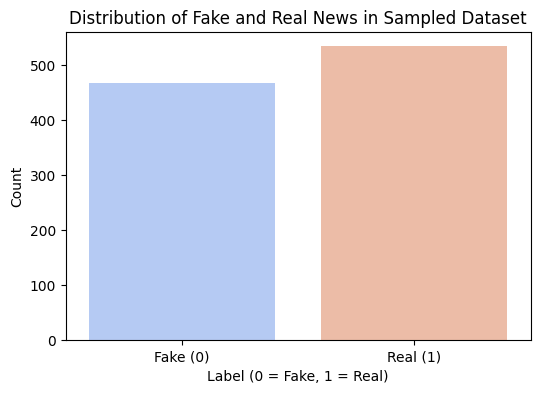

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each class
class_counts = df['label'].value_counts()

# Print the % of fake and real news
print("Fake news %:", class_counts[0] / len(df) * 100)
print("Real news %:", (class_counts[1] / len(df) * 100).round(1))

# Plot the distribution
plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='coolwarm')

plt.title('Distribution of Fake and Real News in Sampled Dataset')
plt.xlabel('Label (0 = Fake, 1 = Real)')
plt.ylabel('Count')
plt.xticks([0, 1], ['Fake (0)', 'Real (1)'])
plt.show()

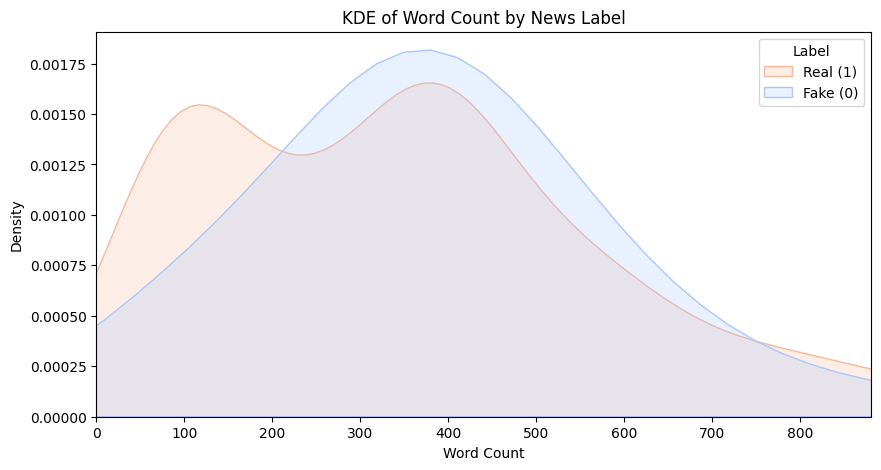

In [ ]:
# Calculate word counts for each article's text
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))

# Plot KDE for Fake (0) and Real (1) news
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df, x='word_count', hue='label', fill=True, common_norm=False, palette='coolwarm')

plt.title('KDE of Word Count by News Label')
plt.xlabel('Word Count')
plt.ylabel('Density')
plt.legend(title='Label', labels=['Real (1)', 'Fake (0)'])
plt.xlim(0, df['word_count'].quantile(0.95)) # Truncate tail to see the distribution clearly
plt.show()

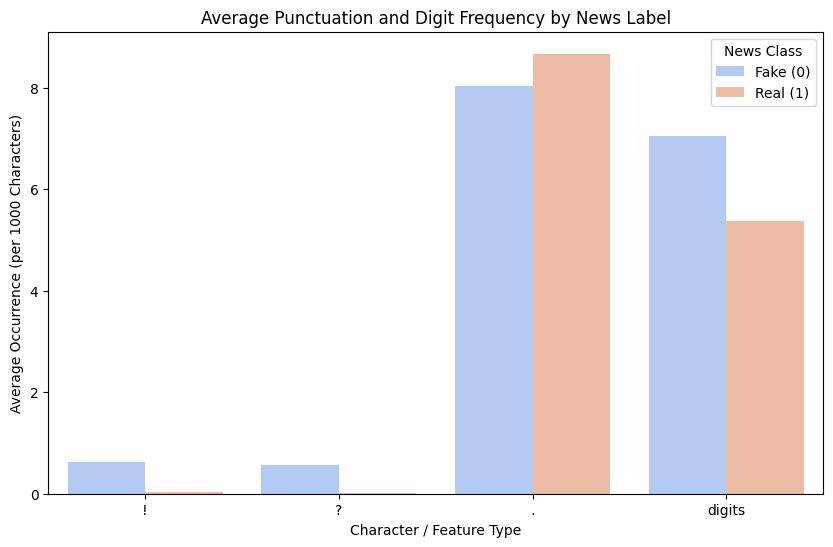

In [ ]:
# Define the characters we want to analyze
chars_to_analyze = ['!', '?', '.', 'digits']

# Helper function to calculate frequency per 1000 characters
def get_char_frequencies(row):
    text = str(row['text'])
    length = len(text)
    if length == 0:
        return {c: 0.0 for c in chars_to_analyze}

    freqs = {}
    for c in ['!', '?', '.']:
        freqs[c] = (text.count(c) / length) * 1000

    digit_count = sum(1 for char in text if char.isdigit())
    freqs['digits'] = (digit_count / length) * 1000
    return freqs

# Apply the function and expand into columns
freq_df = df.apply(get_char_frequencies, axis=1, result_type='expand')
# Map labels to explicit string categories to fix any legend misalignment
freq_df['label'] = df['label'].map({0: 'Fake (0)', 1: 'Real (1)'})

# Melt the dataframe for easy plotting with seaborn
melted_df = freq_df.melt(id_vars='label', value_vars=chars_to_analyze,
                         var_name='Feature', value_name='Frequency per 1000 Chars')

# Plot the grouped bar chart
plt.figure(figsize=(10, 6))
sns.barplot(data=melted_df, x='Feature', y='Frequency per 1000 Chars', hue='label', palette='coolwarm', errorbar=None)

plt.title('Average Punctuation and Digit Frequency by News Label')
plt.xlabel('Character / Feature Type')
plt.ylabel('Average Occurrence (per 1000 Characters)')
plt.legend(title='News Class')
plt.show()

# Model Implementation

In [ ]:
from transformers import pipeline
# https://huggingface.co/adityaG04/fake-news-bert-finetuned
classifier = pipeline("text-classification", model="adityaG04/fake-news-bert-finetuned")

# Print the model labels
print("Model Label Mapping:")
print(classifier.model.config.id2label)

# Map the model to dataset labels (0, 1)
model_to_dataset_label = {
    'LABEL_0': 0,
    'LABEL_1': 1
}

config.json:   0%|          | 0.00/780 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/383 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

Model Label Mapping:
{0: 'LABEL_0', 1: 'LABEL_1'}


In [ ]:
# Simple testing for the model

easy_true = "Donald Trump is the President of the United States in 2026"
easy_fake = "Humans are now extinct in 2026"

test_texts = [easy_fake, easy_true]
true_labels = [0, 1]

# Get predictions
test_preds = classifier(test_texts, truncation=True)

# Extract predicted labels
predicted_labels = [model_to_dataset_label[pred['label']] for pred in test_preds]

# Construct the results table
easy_test_df = pd.DataFrame({
    'text': test_texts,
    'true_label': true_labels,
    'predicted_label': predicted_labels
})

# Display the table
display(easy_test_df)

,text,true_label,predicted_label
0,Humans are now extinct in 2026,0,0
1,Donald Trump is the President of the United St...,1,1


In [ ]:
texts = df["text"].tolist()
true_labels = df['label'].tolist()

# Run the classifier pipeline on the texts
predictions = classifier(texts, truncation=True)

predicted_labels = []
confidence_scores = []

for pred in predictions:
    label_str = pred['label']
    score = pred['score']
    predicted_labels.append(model_to_dataset_label[label_str])
    confidence_scores.append(score)

# Create the results table
results_df = pd.DataFrame({
    'text': texts,
    'true_label': true_labels,
    'predicted_label': predicted_labels,
    'confidence_score': confidence_scores
})

# Display the table
display(results_df)

,text,true_label,predicted_label,confidence_score
0,The game plan for Republicans isn t exactly di...,0,0,0.999950
1,DUBAI (Reuters) - Kuwait s Emir Sheikh Sabah A...,1,1,0.999957
2,oped by laraine c abbey president obamas state...,0,0,0.995910
3,"For years, Fox News hosts have been spewing ra...",0,0,0.999951
4,"Bogor, INDONESIA (Reuters) - Indonesian Presid...",1,1,0.999963
...,...,...,...,...
995,MEXICO CITY (Reuters) - The Mexican government...,1,1,0.999961
996,"Following the situation in Charlottesville, Tr...",0,0,0.999951
997,What do you think of these comments made by Do...,0,0,0.999940
998,"This video was published on March 11, 2016, ex...",0,0,0.999950


# Evaluation and Analysis

Model Accuracy:  0.9910
Model Precision: 0.9870
Model Recall:    0.9962
Model F1 Score:  0.9916


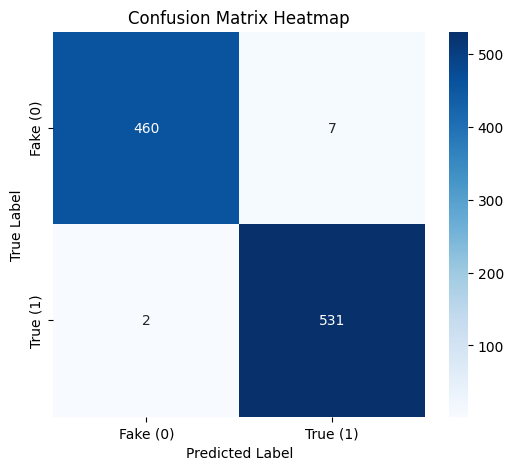

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, f1_score

y_true = results_df['true_label']
y_pred = results_df['predicted_label']

# Calculate the metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Model Accuracy:  {accuracy:.4f}")
print(f"Model Precision: {precision:.4f}")
print(f"Model Recall:    {recall:.4f}")
print(f"Model F1 Score:  {f1:.4f}")


# Plot Confusion Matrix Heatmap
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake (0)', 'True (1)'], yticklabels=['Fake (0)', 'True (1)'])
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


In [ ]:
# Filter the results to find incorrect predictions
wrong_predictions = results_df[results_df['true_label'] != results_df['predicted_label']]
wrong_predictions

,text,true_label,predicted_label,confidence_score
134,share the amish in america have committed the...,0,1,0.838676
203,on november am \nsaturday night live has h...,1,0,0.966002
226,pm again donald trump was not opposed to the ...,0,1,0.731286
247,liberty blitzkrieg october \nthe name peter ...,0,1,0.795107
325,the american medical association defines an al...,0,1,0.682413
675,WATCH: @realDonaldTrump exits his speech in Ca...,0,1,0.997181
772,home breaking news dapl protesters proven ri...,1,0,0.983436
935,The Russian President has immediately sent his...,0,1,0.998050
999,while democrats perpetually circle the wagons ...,0,1,0.729720


# Classification Evaluation

**Correct Examples**

Bogor, INDONESIA (Reuters) - Indonesian President Joko Widodo, leader of the world s largest Muslim-majority nation, onThursday condemned the U.S. decision to recognize Jerusalem as Israel s capital. Indonesia strongly condemns the United States unilateral recognition of Jerusalem as the capital of Israel and asks the U.S. to reconsider the decision, Widodo told a news conference. This can rock global security and stability, he said. **(Predicted True)**

UNITED NATIONS (Reuters) - President Recep Tayyip Erdogan of Turkey on Tuesday said a Kurdish independence referendum in northern Iraq could lead to fresh conflicts in the Middle East. New crises in the region, such as bids for independence, could spark new conflicts and must therefore be avoided at all costs ... We urge Iraq s Kurdish Regional Government to abort the steps they have taken in that direction, Erdogan told the United Nations General Assembly. **(Predicted True)**

oped by laraine c abbey president obamas statement giving up some freedom in exchange for security was a lance through my heart give up **(Predicted Fake)**

**Wrong Examples**

WATCH: @realDonaldTrump exits his speech in California by climbing over a barricade to avoid protesters.WATCH: @realDonaldTrump exits his speech in California by climbing over a barricade to avoid protesters.https://t.co/xOzgokBc2x Fox News (@FoxNews) April 29, 2016 The California GOP Convention is going on and it s more of the same thugs who re using violence and violent rhetoric to stop the support of Republican Donald Trump. One of Trump s supporters was harassed and roughed up today in a show of total intolerance by the left. Here s the moment when anti-#Trump protesters broke through the barricade at #CAGOPConvention @ReutersTV pic.twitter.com/1gyarQYn63 Lily Jamali (@lilyjamali) April 29, 2016 Protesters chanting Make America Mexico Again **(Predicted True)**

on november am saturday night live has helped bring quite a bit of levity to this otherwise horrific election year but in the final episode before the election before we as a nation go to the polls and decide if we want to be extraordinary or deplorable the cast of saturday night live could not help but drop the act and get real with america it began as it normally does with alec baldwins masterful donald trump character and kate mckinnons excellent portrayal of hillary clinton if she spent all day every day mainlining a dangerous mixture of sugar and caffeine i never use emails trump says in the cold opener i use a very private very secure site where one can write whatever they want to and no one can read it its called twitter after he is informed that everyone can see his tweets trump replies really and im still in this thing america you must really hate this lady after a scathing rebuke of the medias decision to ignore trumps cozy relationship with putin the kkk and the fbi and instead focus on something as meaningless as hillary clintons emails something magical happened mckinnon and baldwin dropped the facade and got serious im sorry kate i just hate yelling all this stuff at you like this baldwin says i just feel gross all the time about this dont you all feel gross he added addressing the audience mckinnon agrees and the two embark on a friendship montage through the city before returning to the stage then they dropped perhaps the most important message you will hear this election year none of this would have mattered if you dont vote baldwin says we cant tell you who to vote for but on tuesday we all get a chance to choose what kind of country we want to live in mckinnon finishes theyre right **(Predicted Fake)**

# Conclusions

**Strengths of the model**
*   Pre Trained model on the train split of this dataset with over 24,000 labled news
*   Strong score in all metrics with over 98% in accuracy, recall, precision and f1 score

**Weaknesses of the model**
*   Possibly relies too much on news source artifacts such a (Reuters) in the text to classify real news
*   Unable to fact check teh internet so articles that look fake but are real events may cause the model to answer incorrectly

**Possible Improvements**
*   Add text preprocessing so that @, links and news source like Reutersdo not affect the model
*   Testing the model on other datasets that may have less political news
*   Give the model access to the internet to fact check the text




# Thank You